<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

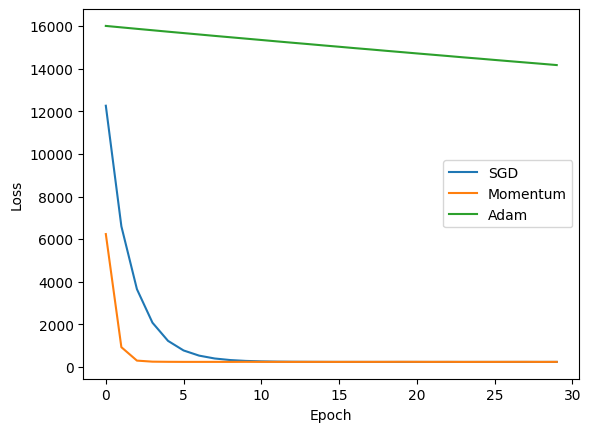

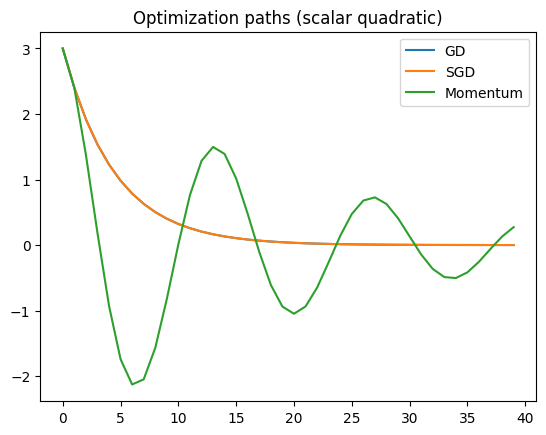

In [1]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
X,y=make_regression(n_samples=700,n_features=4,noise=15,random_state=4); X=X.astype('float32'); y=y.astype('float32')
Xt,Xv,yt,yv=train_test_split(X,y,test_size=.2,random_state=1)
# Optimizer comparison
hist={}
for name,opt in [('SGD',tf.keras.optimizers.SGD(.01)),('Momentum',tf.keras.optimizers.SGD(.01,momentum=.9)),('Adam',tf.keras.optimizers.Adam(.01))]:
 m=tf.keras.Sequential([tf.keras.layers.Input((4,)),tf.keras.layers.Dense(1)]); m.compile(opt,'mse')
 h=m.fit(Xt,yt,validation_data=(Xv,yv),epochs=30,verbose=0); hist[name]=h.history['loss']
for k,v in hist.items(): plt.plot(v,label=k)
plt.legend(); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.show()
# Simple scalar loss optimization traces
for name,lr,mom in [('GD',.1,0),('SGD',.1,0),('Momentum',.1,.9)]:
 x=3.; velocity=0; path=[]
 for _ in range(40): path.append(x); velocity=mom*velocity+lr*2*x; x-=velocity
 plt.plot(path,label=name)
plt.legend(); plt.title('Optimization paths (scalar quadratic)'); plt.show()